## 0. Instalacja zależności

In [1]:
!pip install torch torchvision matplotlib

## 1. Importy, urządzenie i konfiguracja eksperymentu


In [2]:
import copy, math, time
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt

CFG = {
    "epochs": 10,
    "lr": 1e-3,
    "batch_size": 128,
    "n_val": 5000,
    "augment": False,
    "seed": 42,
}

torch.manual_seed(CFG["seed"])
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| urządzenie:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130 | urządzenie: cuda
GPU: Tesla T4


## 2. Dane: CIFAR-10 z podziałem trening / walidacja / test


In [3]:
mean = (0.4914, 0.4822, 0.4465)
std  = (0.2470, 0.2435, 0.2616)

tf_eval = transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean, std)])

tf_train = transforms.Compose(
    ([transforms.RandomCrop(32, padding=4), transforms.RandomHorizontalFlip()] if CFG["augment"] else [])
    + [transforms.ToTensor(), transforms.Normalize(mean, std)]
)

from google.colab import drive
drive.mount('/content/drive')

DATA_ROOT = '/content/drive/MyDrive/cifar10'

import shutil, os
if not os.path.exists('/content/cifar-10-python.tar.gz'):
    shutil.copy(DATA_ROOT + '/cifar-10-python.tar.gz', '/content/')
DATA_ROOT = '/content'

train_full_aug  = torchvision.datasets.CIFAR10(DATA_ROOT, train=True,  download=True, transform=tf_train)
train_full_eval = torchvision.datasets.CIFAR10(DATA_ROOT, train=True,  download=True, transform=tf_eval)
test_ds         = torchvision.datasets.CIFAR10(DATA_ROOT, train=False, download=True, transform=tf_eval)
classes = train_full_eval.classes

g = torch.Generator().manual_seed(CFG["seed"])
perm = torch.randperm(len(train_full_eval), generator=g).tolist()
val_idx, train_idx = perm[:CFG["n_val"]], perm[CFG["n_val"]:]
train_ds = Subset(train_full_aug, train_idx)
val_ds   = Subset(train_full_eval, val_idx)

train_dl = DataLoader(train_ds, batch_size=CFG["batch_size"], shuffle=True,  num_workers=2, pin_memory=True)
val_dl   = DataLoader(val_ds,   batch_size=256, shuffle=False, num_workers=2, pin_memory=True)
test_dl  = DataLoader(test_ds,  batch_size=256, shuffle=False, num_workers=2, pin_memory=True)
print("Klasy:", classes)
print(f"Trening: {len(train_ds)} | Walidacja: {len(val_ds)} | Test: {len(test_ds)}")

Mounted at /content/drive
Klasy: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Trening: 45000 | Walidacja: 5000 | Test: 10000


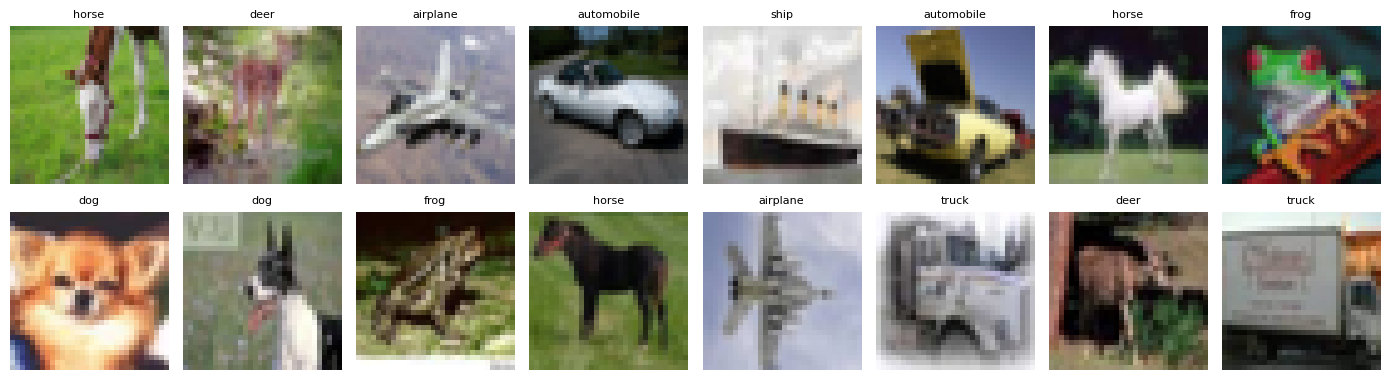

In [4]:
mean_t = torch.tensor(mean).view(3, 1, 1); std_t = torch.tensor(std).view(3, 1, 1)
def denorm(img): return (img * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy()

xb, yb = next(iter(train_dl))
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, img, lb in zip(axes.flat, xb, yb):
    ax.imshow(denorm(img)); ax.set_title(classes[lb], fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

## 3. Modele: MLP i SimpleCNN

In [5]:
class MLP(nn.Module):
    def __init__(self, in_dim=3*32*32, hidden=(512, 256), n_classes=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_dim, hidden[0]), nn.ReLU(),
            nn.Linear(hidden[0], hidden[1]), nn.ReLU(),
            nn.Linear(hidden[1], n_classes),
        )
    def forward(self, x): return self.net(x)

def block(cin, cout):
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
        nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
        nn.MaxPool2d(2),
    )

class SimpleCNN(nn.Module):
    def __init__(self, c1=32, c2=64, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(block(3, c1), block(c1, c2))
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(c2*8*8, 256), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(256, n_classes),
        )
    def forward(self, x): return self.classifier(self.features(x))

def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

mlp_tmp, cnn_tmp = MLP(), SimpleCNN()
print(f"MLP:                   {count_params(mlp_tmp):>10,}")
print(f"CNN część splotowa:    {count_params(cnn_tmp.features):>10,}")
print(f"CNN głowica:           {count_params(cnn_tmp.classifier):>10,}")
print(f"CNN razem:             {count_params(cnn_tmp):>10,}")

MLP:                    1,707,274
CNN część splotowa:        65,952
CNN głowica:            1,051,402
CNN razem:              1,117,354


## 4. Testy kontrolne przed treningiem

In [6]:
# TEST 1: przepływ kształtów przez SimpleCNN
x = torch.randn(4, 3, 32, 32)
for name, layer in cnn_tmp.features.named_children():
    x = layer(x); print("blok", name, tuple(x.shape))
print("logity", tuple(cnn_tmp.classifier(x).shape))

# TEST 2: strata na starcie
crit = nn.CrossEntropyLoss()
xb, yb = next(iter(train_dl))
for name, m in [("MLP", MLP()), ("CNN", SimpleCNN())]:
    m = m.to(device).eval()
    with torch.no_grad():
        print(f"{name}: strata na starcie {crit(m(xb.to(device)), yb.to(device)).item():.3f}"
              f" (oczekiwane ok. {math.log(10):.3f})")

# TEST 3: przeuczenie jednej paczki
m = SimpleCNN().to(device); opt = torch.optim.Adam(m.parameters(), lr=1e-3)
x32, y32 = xb[:32].to(device), yb[:32].to(device)
m.train()
for step in range(101):
    opt.zero_grad(); loss = crit(m(x32), y32); loss.backward(); opt.step()
    if step % 25 == 0: print(f"krok {step:3d} | strata {loss.item():.4f}")

blok 0 (4, 32, 16, 16)
blok 1 (4, 64, 8, 8)
logity (4, 10)
MLP: strata na starcie 2.309 (oczekiwane ok. 2.303)
CNN: strata na starcie 2.303 (oczekiwane ok. 2.303)
krok   0 | strata 2.3737
krok  25 | strata 0.0027
krok  50 | strata 0.0002
krok  75 | strata 0.0002
krok 100 | strata 0.0000


## 5. Funkcje treningu i ewaluacji

In [7]:
def sync():
    if device == "cuda": torch.cuda.synchronize()

def train_one_epoch(model, dl, opt, crit):
    model.train()
    s = n = 0
    for xb, yb in dl:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad()
        loss = crit(model(xb), yb)
        loss.backward()
        opt.step()
        s += loss.item() * yb.size(0); n += yb.size(0)
    return s / n

@torch.no_grad()
def evaluate(model, dl, crit):
    model.eval(); s = c = n = 0
    for xb, yb in dl:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        s += crit(out, yb).item() * yb.size(0)
        c += (out.argmax(1) == yb).sum().item(); n += yb.size(0)
    return s / n, c / n

train_eval_dl = DataLoader(Subset(train_full_eval, train_idx), batch_size=256,
                           shuffle=False, num_workers=2, pin_memory=True)

def fit(model, cfg=CFG):
    torch.manual_seed(cfg["seed"])
    model = model.to(device)
    crit = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc"]}
    best = {"val_acc": -1.0, "epoch": 0, "state": None}
    train_time = eval_time = 0.0
    for epoch in range(1, cfg["epochs"] + 1):
        sync(); t0 = time.time()
        train_one_epoch(model, train_dl, opt, crit)
        sync(); t1 = time.time()
        tr_loss, tr_acc = evaluate(model, train_eval_dl, crit)
        va_loss, va_acc = evaluate(model, val_dl, crit)
        sync(); t2 = time.time()
        train_time += t1 - t0; eval_time += t2 - t1
        for k, v in zip(hist, [tr_loss, tr_acc, va_loss, va_acc]): hist[k].append(v)
        if va_acc > best["val_acc"]:
            best = {"val_acc": va_acc, "epoch": epoch, "state": copy.deepcopy(model.state_dict())}
        print(f"  epoka {epoch:2d} | strata tr {tr_loss:.3f} wal {va_loss:.3f}"
              f" | acc tr {tr_acc*100:5.2f}% wal {va_acc*100:5.2f}%")
    model.load_state_dict(best["state"])
    return {"model": model, "hist": hist, "best": best,
            "train_time": train_time, "eval_time": eval_time}

## 6. Trening: MLP i SimpleCNN


In [8]:
print("== MLP ==")
res_mlp = fit(MLP())
print("\n== SimpleCNN ==")
res_cnn = fit(SimpleCNN())

== MLP ==
  epoka  1 | strata tr 1.448 wal 1.523 | acc tr 48.92% wal 46.26%
  epoka  2 | strata tr 1.346 wal 1.471 | acc tr 52.58% wal 48.88%
  epoka  3 | strata tr 1.210 wal 1.402 | acc tr 57.28% wal 51.70%
  epoka  4 | strata tr 1.155 wal 1.421 | acc tr 59.34% wal 50.54%
  epoka  5 | strata tr 1.049 wal 1.372 | acc tr 62.73% wal 52.70%
  epoka  6 | strata tr 0.952 wal 1.385 | acc tr 66.44% wal 52.90%
  epoka  7 | strata tr 0.886 wal 1.417 | acc tr 68.70% wal 53.50%
  epoka  8 | strata tr 0.836 wal 1.464 | acc tr 70.59% wal 53.54%
  epoka  9 | strata tr 0.774 wal 1.532 | acc tr 72.58% wal 52.30%
  epoka 10 | strata tr 0.697 wal 1.569 | acc tr 75.43% wal 53.36%

== SimpleCNN ==
  epoka  1 | strata tr 0.992 wal 1.010 | acc tr 64.56% wal 64.02%
  epoka  2 | strata tr 0.812 wal 0.858 | acc tr 71.57% wal 69.86%
  epoka  3 | strata tr 0.651 wal 0.729 | acc tr 76.73% wal 74.38%
  epoka  4 | strata tr 0.578 wal 0.692 | acc tr 79.47% wal 75.80%
  epoka  5 | strata tr 0.519 wal 0.685 | acc tr 8

## 7. Końcowa ocena na zbiorze testowym


In [9]:
crit = nn.CrossEntropyLoss()
rows = []
for name, r in [("MLP", res_mlp), ("CNN", res_cnn)]:
    m, h, b = r["model"], r["hist"], r["best"]
    _, test_acc = evaluate(m, test_dl, crit)
    i = b["epoch"] - 1
    rows.append((name, count_params(m), b["epoch"], h["train_acc"][i], b["val_acc"],
                 h["train_acc"][i] - b["val_acc"], test_acc, r["train_time"]))

print(f"{'model':5} | {'parametry':>10} | {'epoka':>5} | {'acc tr':>7} | {'acc wal':>7} |"
      f" {'przerwa':>7} | {'acc test':>8} | {'czas tr [s]':>11}")
print("-" * 86)
for n, p, e, tr, va, gap, te, t in rows:
    print(f"{n:5} | {p:>10,} | {e:>5} | {tr*100:6.2f}% | {va*100:6.2f}% |"
          f" {gap*100:6.2f}% | {te*100:7.2f}% | {t:>11.1f}")
print(f"\nCNN: część splotowa {count_params(res_cnn['model'].features):,},"
      f" głowica {count_params(res_cnn['model'].classifier):,}")
print("Klasyfikator losowy: 10.00%")

model |  parametry | epoka |  acc tr | acc wal | przerwa | acc test | czas tr [s]
--------------------------------------------------------------------------------------
MLP   |  1,707,274 |     8 |  70.59% |  53.54% |  17.05% |   52.03% |        94.1
CNN   |  1,117,354 |     9 |  89.35% |  79.66% |   9.69% |   79.59% |       105.1

CNN: część splotowa 65,952, głowica 1,051,402
Klasyfikator losowy: 10.00%


## 8. Krzywe uczenia

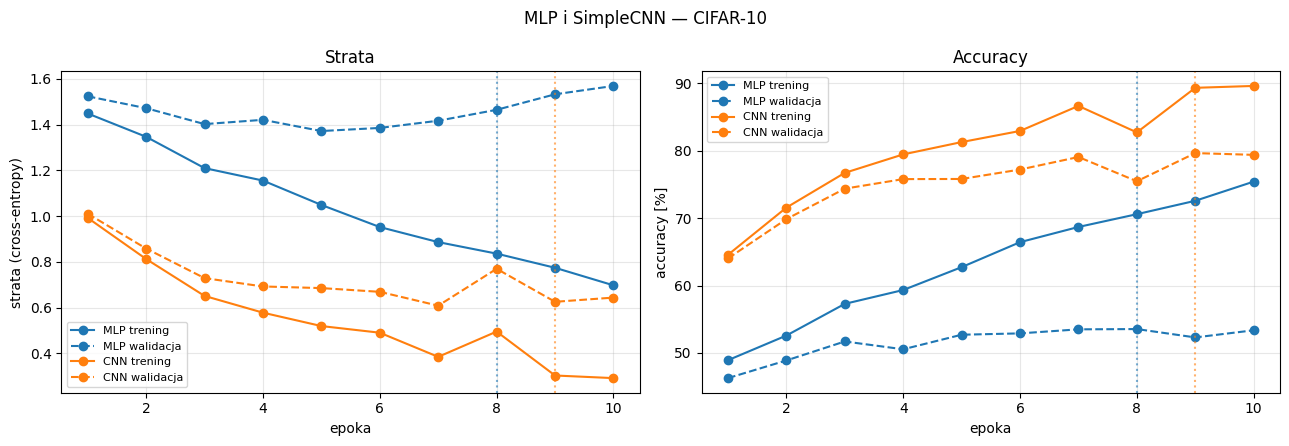

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for name, r, color in [("MLP", res_mlp, "tab:blue"), ("CNN", res_cnn, "tab:orange")]:
    h = r["hist"]; ep = range(1, len(h["train_loss"]) + 1)
    ax1.plot(ep, h["train_loss"], "-o", color=color, label=f"{name} trening")
    ax1.plot(ep, h["val_loss"], "--o", color=color, label=f"{name} walidacja")
    ax2.plot(ep, [a*100 for a in h["train_acc"]], "-o", color=color, label=f"{name} trening")
    ax2.plot(ep, [a*100 for a in h["val_acc"]], "--o", color=color, label=f"{name} walidacja")
    for ax in (ax1, ax2): ax.axvline(r["best"]["epoch"], color=color, ls=":", alpha=0.6)
ax1.set(xlabel="epoka", ylabel="strata (cross-entropy)", title="Strata")
ax2.set(xlabel="epoka", ylabel="accuracy [%]", title="Accuracy")
for ax in (ax1, ax2): ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.suptitle("MLP i SimpleCNN - CIFAR-10"); plt.tight_layout(); plt.show()

## 9. Mapy cech pierwszej i głębszej warstwy splotowej


mapy warstwy 1: (32, 32, 32) | mapy warstwy głębszej: (64, 16, 16)


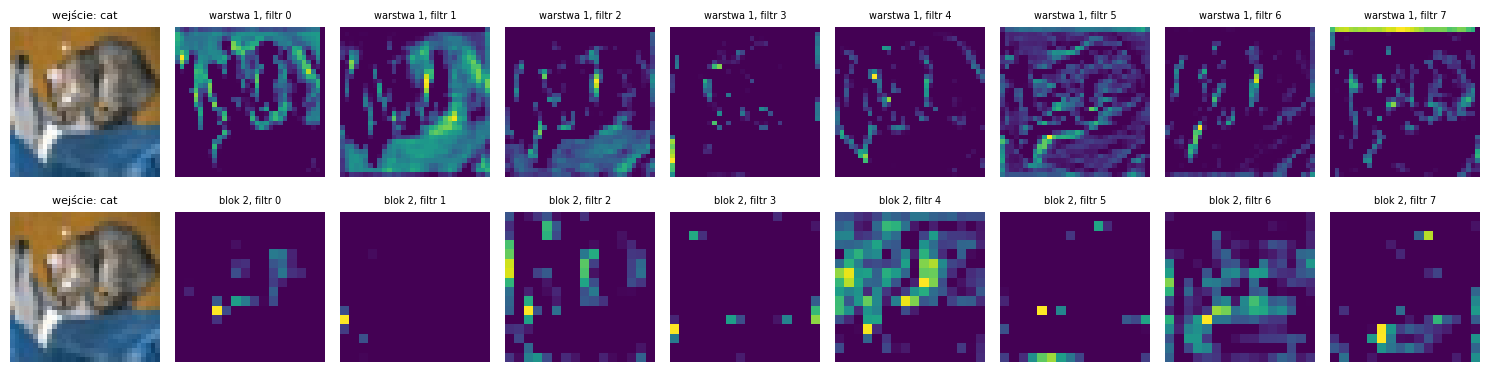

In [11]:
cnn = res_cnn["model"].eval()
img, label = test_ds[0]
x = img.unsqueeze(0).to(device)
with torch.no_grad():
    maps1 = torch.relu(cnn.features[0][0](x))[0].cpu()
    after_block1 = cnn.features[0](x)
    maps2 = torch.relu(cnn.features[1][0](after_block1))[0].cpu()
print("mapy warstwy 1:", tuple(maps1.shape), "| mapy warstwy głębszej:", tuple(maps2.shape))

fig, axes = plt.subplots(2, 9, figsize=(15, 4))
for row, (maps, title) in enumerate([(maps1, "warstwa 1"), (maps2, "blok 2")]):
    axes[row, 0].imshow(denorm(img)); axes[row, 0].axis("off")
    axes[row, 0].set_title(f"wejście: {classes[label]}", fontsize=8)
    for i, ax in enumerate(axes[row, 1:]):
        ax.imshow(maps[i], cmap="viridis"); ax.axis("off")
        ax.set_title(f"{title}, filtr {i}", fontsize=7)
plt.tight_layout(); plt.show()

## 10. Zakres dodatkowy: wpływ liczby filtrów


In [13]:
RUN_EXTRA = True

if RUN_EXTRA:
    extra = []
    for c1, c2 in [(16, 32), (32, 64), (64, 128)]:
        print(f"\n== SimpleCNN c1={c1}, c2={c2} ==")
        r = fit(SimpleCNN(c1, c2))
        extra.append((c1, c2, count_params(r["model"]), r["best"]["val_acc"], r["train_time"]))
    print(f"\n{'c1/c2':>8} | {'parametry':>10} | {'acc wal':>7} | {'czas tr [s]':>11}")
    for c1, c2, p, va, t in extra:
        print(f"{f'{c1}/{c2}':>8} | {p:>10,} | {va*100:6.2f}% | {t:>11.1f}")


== SimpleCNN c1=16, c2=32 ==
  epoka  1 | strata tr 1.048 wal 1.058 | acc tr 62.28% wal 62.02%
  epoka  2 | strata tr 0.848 wal 0.897 | acc tr 70.21% wal 68.62%
  epoka  3 | strata tr 0.685 wal 0.771 | acc tr 75.95% wal 72.24%
  epoka  4 | strata tr 0.698 wal 0.800 | acc tr 74.82% wal 71.50%
  epoka  5 | strata tr 0.590 wal 0.742 | acc tr 78.61% wal 74.58%
  epoka  6 | strata tr 0.529 wal 0.702 | acc tr 81.34% wal 75.26%
  epoka  7 | strata tr 0.472 wal 0.686 | acc tr 83.34% wal 76.64%
  epoka  8 | strata tr 0.485 wal 0.745 | acc tr 82.85% wal 76.12%
  epoka  9 | strata tr 0.452 wal 0.728 | acc tr 84.18% wal 75.68%
  epoka 10 | strata tr 0.390 wal 0.709 | acc tr 86.18% wal 75.88%

== SimpleCNN c1=32, c2=64 ==
  epoka  1 | strata tr 1.009 wal 1.021 | acc tr 63.82% wal 63.80%
  epoka  2 | strata tr 0.844 wal 0.894 | acc tr 70.49% wal 68.38%
  epoka  3 | strata tr 0.668 wal 0.748 | acc tr 76.58% wal 73.52%
  epoka  4 | strata tr 0.599 wal 0.715 | acc tr 78.34% wal 74.42%
  epoka  5 | str